# Assignment 07: A First Machine Learning SDM

## BIO597 Spatial Analysis of Biodiversity

Repeat the workflow from Lab 07 for a Maine amphibian species of your choice. Focus on understanding what the model learns and what its predictions mean. You may reuse code from the lab.

## Deliverable

Submit this notebook with your completed code, figures, and short written answers, plus a saved suitability raster. There is no need to tune model settings or compare additional algorithms.


In [1]:
pip install rioxarray

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 39.1/39.1 MB 125.4 MB/s  0:00:00m0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 109.8 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4/4 [rioxarray]/4 [xarray]o]
Note: you may need to restart the kernel to use updated packages.


## 1. Import packages and load the data

Run this notebook from `docs/assignments`. Import the packages used in Lab 07. Load the two supplied files and display species counts.


In [2]:
# Import the packages used in Lab 07.
import geopandas as gpd
import matplotlib.pyplot as plt
import pandas as pd
import rioxarray
import xarray as xr

from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error
from sklearn.model_selection import train_test_split





amphibians = gpd.read_file("../data/amphibians+bioclim.geojson")
climate = xr.open_dataset("../data/maine_bioclim.nc")

# Display species counts.
amphibians["species"].value_counts().head(12)

species
Pseudacris crucifer          1722
Aquarana clamitans           1656
Anaxyrus americanus          1581
Boreorana sylvatica          1522
Lithobates catesbeianus      1451
Ambystoma maculatum          1214
Plethodon cinereus           1125
Lithobates palustris         1007
Dryophytes versicolor         714
Notophthalmus viridescens     573
Lithobates pipiens            325
Hemidactylium scutatum        226
Name: count, dtype: int64

## 2. Choose your species

Choose a common species other than the wood frog, with at least 500 records. Keep records with coordinate uncertainty below 100 m, as in the lab.


In [3]:
target_species = "Aquarana clamitans"

# Select your species and apply the uncertainty filter.
presence = amphibians[amphibians["species"] == target_species].copy()
presence = presence[presence["coordinateUncertaintyInMeters"] < 100].copy()

# Store the result as presence and print its record count.
print("Number of records:", len(presence))


Number of records: 1429


**Why did you choose this species?** Write one or two sentences.

I chose the Green Frog mainly due to the high level of observations it has. 

## 3. Keep all climate variables available

As in Lab 07, make a list called `climate_variables` containing `bio_1` through `bio_19`. We will choose the model predictors after preparing the modeling table.


In [4]:
# Create climate_variables and display these columns at your species' records.
climate_variables = ["bio_" + str(number) for number in range(1, 20)]

presence[climate_variables].head()



,bio_1,bio_2,bio_3,bio_4,bio_5,bio_6,bio_7,bio_8,bio_9,bio_10,bio_11,bio_12,bio_13,bio_14,bio_15,bio_16,bio_17,bio_18,bio_19
1,6.332833,12.243667,29.463055,1034.367798,26.612000,-14.944000,41.556000,1.783333,-5.721334,18.769333,-6.940667,1051.0,106.0,65.0,12.902308,294.0,213.0,277.0,229.0
19,6.991422,10.311275,27.661617,945.672241,25.482353,-11.794118,37.276470,-2.072549,18.374510,18.374510,-5.050981,1358.0,151.0,74.0,18.804165,416.0,259.0,259.0,369.0
26,4.899500,12.165667,29.115612,1052.887329,25.063999,-16.719999,41.783997,17.463333,-7.532000,17.463333,-8.572000,1089.0,110.0,65.0,14.460333,304.0,216.0,304.0,232.0
32,6.652667,12.318000,30.532421,987.619568,26.375999,-13.968000,40.344002,2.300000,17.676666,18.556667,-5.925333,1183.0,126.0,84.0,11.761146,341.0,266.0,279.0,286.0
33,6.153274,10.233929,28.270521,924.512817,23.985714,-12.214286,36.200001,-2.710714,17.153572,17.153572,-5.666667,1205.0,123.0,77.0,15.422133,357.0,242.0,242.0,319.0


## 4. Prepare presence and background tables

Use the prepared climate values at the occurrence records directly, as in the revised lab. We do not need to match records to raster cells or join tables by coordinates.

The code below prepares the climate grid for background sampling and mapping. Each grid row is a cell, but each presence row is an occurrence record. Several presence records may therefore describe the same climate cell.


In [5]:
grid = climate[climate_variables].to_dataframe().reset_index()
grid = grid[["x", "y"] + climate_variables]
grid = grid.dropna(subset=climate_variables)
grid.head()


,x,y,bio_1,bio_2,bio_3,bio_4,bio_5,bio_6,bio_7,bio_8,...,bio_10,bio_11,bio_12,bio_13,bio_14,bio_15,bio_16,bio_17,bio_18,bio_19
146,-69.229167,47.437500,2.610167,10.487667,24.623560,1133.966675,23.148001,-19.444000,42.592003,16.066000,...,16.066000,-12.065333,1093.0,110.0,67.0,13.786905,317.0,227.0,317.0,231.0
147,-69.187500,47.437500,2.620167,10.551667,24.738974,1134.299316,23.200001,-19.452000,42.652000,16.072001,...,16.072001,-12.078667,1080.0,110.0,66.0,14.227962,316.0,223.0,316.0,228.0
148,-69.145833,47.437500,2.786333,10.607333,24.855499,1130.561035,23.344000,-19.332001,42.676003,16.170000,...,16.170000,-11.888667,1043.0,108.0,63.0,14.921009,307.0,211.0,307.0,222.0
246,-69.270833,47.395833,2.161333,10.447333,24.595850,1134.809448,22.668001,-19.808001,42.476002,15.676667,...,15.676667,-12.473333,1130.0,116.0,69.0,14.441315,332.0,233.0,332.0,237.0
247,-69.229167,47.395833,2.441500,10.566333,24.831577,1130.958252,22.968000,-19.584000,42.552002,15.872000,...,15.872000,-12.190666,1099.0,113.0,67.0,14.589335,323.0,226.0,323.0,231.0


In [6]:
# Keep the prepared predictors and remove records with missing climate values.
presence_data = presence[climate_variables].dropna().copy()
presence_data["observed"] = 1

print("Usable presence records:", len(presence_data))
presence_data.head()


Usable presence records: 1429


,bio_1,bio_2,bio_3,bio_4,bio_5,bio_6,bio_7,bio_8,bio_9,bio_10,bio_11,bio_12,bio_13,bio_14,bio_15,bio_16,bio_17,bio_18,bio_19,observed
1,6.332833,12.243667,29.463055,1034.367798,26.612000,-14.944000,41.556000,1.783333,-5.721334,18.769333,-6.940667,1051.0,106.0,65.0,12.902308,294.0,213.0,277.0,229.0,1
19,6.991422,10.311275,27.661617,945.672241,25.482353,-11.794118,37.276470,-2.072549,18.374510,18.374510,-5.050981,1358.0,151.0,74.0,18.804165,416.0,259.0,259.0,369.0,1
26,4.899500,12.165667,29.115612,1052.887329,25.063999,-16.719999,41.783997,17.463333,-7.532000,17.463333,-8.572000,1089.0,110.0,65.0,14.460333,304.0,216.0,304.0,232.0,1
32,6.652667,12.318000,30.532421,987.619568,26.375999,-13.968000,40.344002,2.300000,17.676666,18.556667,-5.925333,1183.0,126.0,84.0,11.761146,341.0,266.0,279.0,286.0,1
33,6.153274,10.233929,28.270521,924.512817,23.985714,-12.214286,36.200001,-2.710714,17.153572,17.153572,-5.666667,1205.0,123.0,77.0,15.422133,357.0,242.0,242.0,319.0,1


In [7]:
# Sample available environments, using one background row per presence record.
background = grid.sample(n=len(presence_data), random_state=597).copy()
background["observed"] = 0

model_data = pd.concat([presence_data, background], ignore_index=True)
model_data["observed"].value_counts()


observed
1    1429
0    1429
Name: count, dtype: int64

The missing-value cleanup keeps incomplete presence records out of both models. `random_state=597` makes the background sample repeatable. Background is sampled from the full valid grid, so it can include cells where the species has been recorded. It represents available environments, not confirmed absences.

## 5. Define predictors and response

Start with `features = ["bio_1"]`, annual mean temperature, to connect with last week's model. Set `X` to this predictor column and `y` to the `observed` labels. Only the selected climate columns belong in `X`; the background's coordinate columns are for mapping.


In [8]:
# Set features to bio_1 only.
features = ["bio_1"]


# Define X and y, following Lab 07.
X = model_data[features]
y = model_data["observed"]

X.head()

,bio_1
0,6.332833
1,6.991422
2,4.899500
3,6.652667
4,6.153274


## 6. Split, fit, and predict

Split `model_data` into `train_data` (75%) and `test_data` (25%) with `random_state=597``, as in the lab

Fit a `RandomForestRegressor` using only `bio_1`, with 100 trees, `min_samples_leaf=5`, and `random_state=597`.


In [9]:
# Split model_data into train_data and test_data.

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=597,
)

print("Training cells:", len(X_train))
print("Test cells:", len(X_test))

# Define X_train, X_test, y_train, and y_test using features and observed.
# Create model and fit it to the training data.
model = RandomForestRegressor(
    n_estimators=100,
    min_samples_leaf=5,
    random_state=42,
)
model.fit(X_train, y_train)
# Predict suitability for X_test.
test_prediction = model.predict(X_test)


Training cells: 2143
Test cells: 715


## 7. Check the BIO1-only predictions

Calculate mean absolute error and store it as `bio1_error`. Plot test predictions for presence and background cells in overlapping histograms, as in the lab.


BIO1-only MAE: 0.305


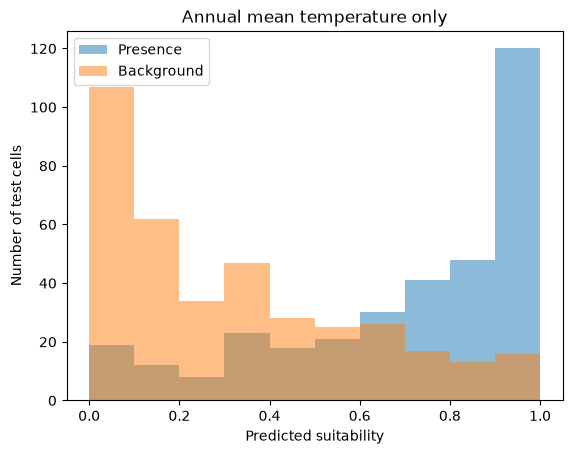

In [10]:
# Calculate and print bio1_error.

bio1_error = mean_absolute_error(y_test, test_prediction)
print("BIO1-only MAE:", round(bio1_error, 3))
# Plot the predicted score distributions for the two test labels.
plt.hist(test_prediction[y_test == 1], alpha=0.5, label="Presence")
plt.hist(test_prediction[y_test == 0], alpha=0.5, label="Background")
plt.xlabel("Predicted suitability")
plt.ylabel("Number of test cells")
plt.title("Annual mean temperature only")
plt.legend()
plt.show()

**Interpretation:** Do test presence cells generally receive higher scores? Why should we use withheld cells to check the model?

Yes test cells generally have much higher scores compared to background. We should use withheld cells to check the model because it was not trained on these cells. 

## 8. Add precipitation and compare MAE

Choose three new bioclim variables to test (you can look up the meanings of the variables
in the [bioclimatic variables documentation](https://www.worldclim.org/data/bioclim.html))

Change `features` to `["bio_X", "bio_XX", "bio_XX"]` (replacing the "X" values with the integer
index of the bioclim variables you chose). Create a new feature table (`X`) selecting just the features of interest and perform a new test/train split. Fit a new forest with these three predictors and calculate `three_variable_error`. Print both MAEs together.


In [11]:
# Select the three predictor columns from the existing training and test tables.
features = ["bio_5", "bio_6", "bio_12"]

# Fit three_variable_model and predict the same withheld cells.
X = model_data[features]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=597,
)

three_variable_model = RandomForestRegressor(
    n_estimators=100, min_samples_leaf=5, random_state=2,
)

three_variable_model.fit(X_train, y_train)
three_variable_prediction = three_variable_model.predict(X_test)
# Calculate three_variable_error and print it beside bio1_error.
three_variable_error = mean_absolute_error(y_test, three_variable_prediction)

print("BIO1-only MAE:", round(bio1_error, 3))
print("BIO5 + BIO6 + BIO12 MAE:", round(three_variable_error, 3))


BIO1-only MAE: 0.305
BIO5 + BIO6 + BIO12 MAE: 0.275


**Interpretation:** Did the three new bioclim variables improve prediction error for your species? Explain why the new conditions you chose may or may not be relevant biologically.
Yes the new variables improved prediction error, dropping from .305 to .275. They prefer warm temperatures so the hottest temp in the highest month may predict high suitibility while the coldest temp in the coldest month may make a region unsuitable. I included percipitation because they require freshwater. 
## 9. Make a suitability map

Fit a new `final_model` using all modeling rows and the three predictors. Predict scores for `grid[features]`. Use the plotting recipe from Lab 07 to turn the suitability column into a raster and map it from 0 to 1.


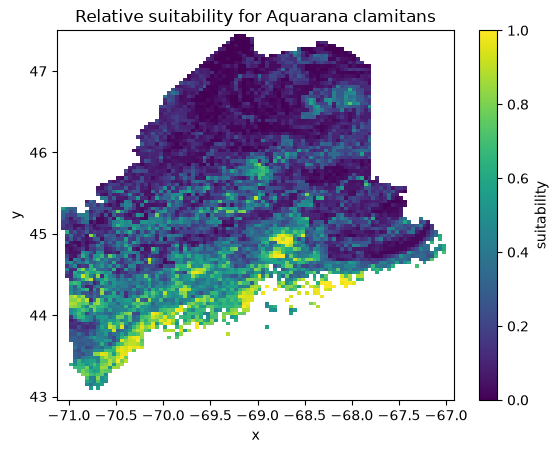

In [12]:
# Update X to include all three predictors.

X = model_data[features]

# Fit final_model with the same forest settings.
final_model = RandomForestRegressor(
    n_estimators=100, min_samples_leaf=5, random_state=597,
)

# Add grid["suitability"], convert it to a raster named suitability, and plot it.
final_model.fit(X, y)
grid["suitability"] = final_model.predict(grid[features])


suitability = grid.set_index(["y", "x"])["suitability"].to_xarray()
suitability = suitability.reindex(y=climate.y, x=climate.x)

suitability.plot(vmin=0, vmax=1, cmap="viridis")
plt.title(f"Relative suitability for {target_species}")
plt.show()

**Interpretation:** Which parts of Maine receive high scores? Why should we describe these as relative suitability rather than probability of occurrence?

The coast appears to recieve the highest scores. These are relitve suitablity becasue we are just modeling weather the environment in a particular place will be suitable when compared to the rest of maine.. Not how likely a it is that that environment will have the organism. 

## 10. Plot variable importance

Use `final_model.feature_importances_` and `pd.Series()` as in the lab to make a bar plot for the three predictors.


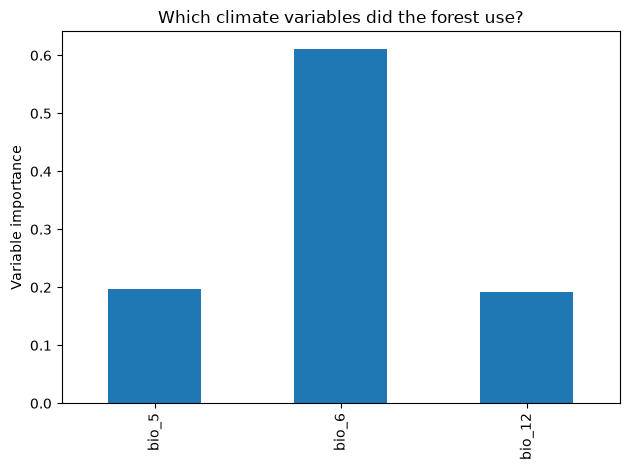

In [13]:
# Make and label a variable-importance plot.
importance = pd.Series(final_model.feature_importances_, index=features)
importance.plot.bar()
plt.ylabel("Variable importance")
plt.title("Which climate variables did the forest use?")
plt.tight_layout()
plt.show()


**Interpretation:** Which variable did your forest use most? Give one reason why this does not establish an ecological cause.

## 11. Save your map

Save `suitability` as `Assignment07_suitability.tif` using the same CRS and export commands as the lab.


In [16]:
# Assign EPSG:4326 and save the suitability raster.

suitability = suitability.rio.write_crs("EPSG:4326")
suitability.rio.to_raster("Assignment_07_suitability.tif")


## 12. Run the training and prediction again including all 19 bioclim variables

**Think about:** Do you predict that more variables will improve the MAE of the model?

BIO1-only MAE: 0.305
BIO1 + BIO12 + BIO15 MAE: 0.275
all variables:  0.276


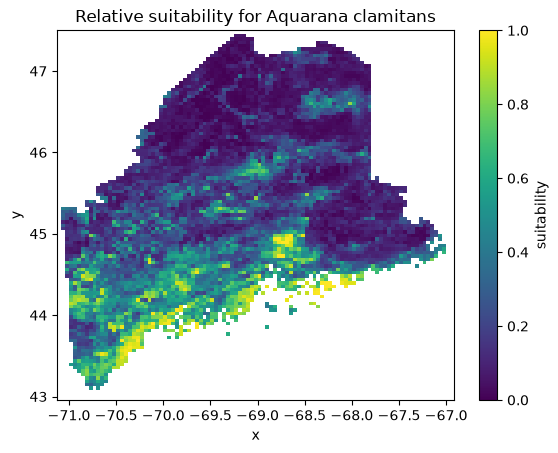

In [15]:
# Run the full analysis again but this time include all 19 bioclim variables

# Select the three predictor columns from the existing training and test tables.
features_all = ["bio_1", "bio_2", "bio_3", "bio_4", "bio_5", "bio_6", "bio_7", "bio_8", "bio_9", "bio_10", "bio_11","bio_12", "bio_13","bio_14","bio_15", "bio_16","bio_17","bio_18","bio_19",]

# Fit three_variable_model and predict the same withheld cells.
X = model_data[features_all]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=597,
)

all_variable_model = RandomForestRegressor(
    n_estimators=100, min_samples_leaf=5, random_state=2,
)

all_variable_model.fit(X_train, y_train)
all_variable_prediction = all_variable_model.predict(X_test)
# Calculate three_variable_error and print it beside bio1_error.
all_variable_error = mean_absolute_error(y_test, all_variable_prediction)

print("BIO1-only MAE:", round(bio1_error, 3))
print("BIO1 + BIO12 + BIO15 MAE:", round(three_variable_error, 3))
print("all variables: ", round(all_variable_error, 3))

X = model_data[features_all]

# Fit final_model with the same forest settings.
final_model = RandomForestRegressor(
    n_estimators=100, min_samples_leaf=5, random_state=597,
)



final_model.fit(X, y)
grid["suitability"] = final_model.predict(grid[features_all])

suitability = grid.set_index(["y", "x"])["suitability"].to_xarray()
suitability = suitability.reindex(y=climate.y, x=climate.x)

suitability.plot(vmin=0, vmax=1, cmap="viridis")
plt.title(f"Relative suitability for {target_species}")
plt.show()


## Final reflection

Answer in two or three sentences per question.

1. How does this week's BIO1-only random forest differ from last week's hand-built temperature curve?

The random forest model is a machine learning that is a black box with no equation to see. Our temperature curve had an equation that we calculated and we may be able to better understand how each input modifies the equation. 


2. What did the comparison with three predictors teach you? Would you expect more predictors always to reduce test error?


The comparison between 1/3/all predictors tought me that 1 predictor is likely not enough to understand frog suitablity. Beyond mean temperature other things need to be considered like percipitation or min/max temps. Despite this, including more predictors will not always reduce error because more predictors can increase error despite better predictive power.

3. Several presence records can share a climate cell. Why might a random split then make prediction look easier than predicting a new location?

Randomly splitting means you may be modeling on a climate cell where you confirmed presence and then predicting on it with that confirmation incorpareted into the model. This would result in the model predicting presence better then if it was a truly new location. 

4. Name one habitat variable or sampling issue missing from your model. How might it affect the map?
One habitat variable that would be crucial is location of freshwater bodies. the green frog is heavily associated with fresh bodies of water and this would likely be an extremely strong predictor. Possibly moving the higher suitablity off the coast and towards the lakes. 
## Submit your work

Restart the kernel and run the notebook from top to bottom. Check your figures, written answers, both MAEs, and saved raster. Commit and push the notebook and raster to your class GitHub repository.

```bash
git add docs/assignments/Assignment-07-MachineLearningSDM.ipynb docs/assignments/Assignment07_suitability.tif
git commit -m "Complete machine learning SDM assignment"
git push
```
